# E-Commerce Supply Chain Project

In [3]:
import pandas as pd
import plotly.express as px
import plotly.io as pio
import plotly.graph_objects as go
pio.templates.defaults="plotly_white"

In [4]:
import pandas as pd
import numpy as np
import random
from datetime import datetime, timedelta

# =========================================================
# E-COMMERCE SUPPLY CHAIN - LARGE MESSY DATASET
# =========================================================

np.random.seed(42)
random.seed(42)

# Number of original records
n = 5000

# ---------------------------------------------------------
# Categories / Product Types
# ---------------------------------------------------------

product_types = [
    "Electronics",
    "Clothing",
    "Beauty",
    "Home & Kitchen",
    "Sports",
    "Toys",
    "Books",
    "Grocery"
]

customer_demographics = [
    "18-25",
    "26-35",
    "36-45",
    "46-55",
    "56+"
]

locations = [
    "New York",
    "Los Angeles",
    "Chicago",
    "Houston",
    "Dallas",
    "Seattle",
    "Miami",
    "Boston",
    "Denver",
    "Atlanta",
    "Phoenix",
    "San Francisco",
    "London",
    "Toronto",
    "Sydney"
]

transportation_modes = [
    "Road",
    "Air",
    "Rail",
    "Sea"
]

routes = [
    "Route-A",
    "Route-B",
    "Route-C",
    "Route-D",
    "Route-E",
    "Route-F",
    "Route-G"
]

inspection_results = [
    "Pass",
    "Fail",
    "Pending"
]

# ---------------------------------------------------------
# Product names
# ---------------------------------------------------------

product_names = {
    "Electronics": [
        "Smartphone",
        "Laptop",
        "Wireless Earbuds",
        "Smart Watch",
        "Bluetooth Speaker"
    ],
    "Clothing": [
        "T-Shirt",
        "Jeans",
        "Jacket",
        "Hoodie",
        "Sneakers"
    ],
    "Beauty": [
        "Face Cream",
        "Shampoo",
        "Perfume",
        "Lipstick",
        "Face Wash"
    ],
    "Home & Kitchen": [
        "Mixer Grinder",
        "Cookware Set",
        "Coffee Maker",
        "Air Fryer",
        "Water Bottle"
    ],
    "Sports": [
        "Cricket Bat",
        "Football",
        "Yoga Mat",
        "Tennis Racket",
        "Dumbbells"
    ],
    "Toys": [
        "Remote Car",
        "Puzzle Set",
        "Action Figure",
        "Board Game",
        "Building Blocks"
    ],
    "Books": [
        "Business Book",
        "Novel",
        "Science Book",
        "Programming Book",
        "History Book"
    ],
    "Grocery": [
        "Rice",
        "Coffee",
        "Tea",
        "Cereal",
        "Cooking Oil"
    ]
}

# ---------------------------------------------------------
# Generate dataset
# ---------------------------------------------------------

data = []

for i in range(n):

    product_type = random.choice(product_types)

    product_name = random.choice(product_names[product_type])

    sku = f"SKU-{10000 + random.randint(1, 9999)}"

    # Product price
    price = round(random.uniform(5, 2500), 2)

    # Availability
    availability = random.choice([
        "In Stock",
        "Out of Stock",
        "Limited Stock"
    ])

    # Number of products sold
    number_sold = random.randint(1, 1000)

    # Revenue
    revenue = round(price * number_sold * random.uniform(0.75, 1.05), 2)

    # Customer demographics
    demographics = random.choice(customer_demographics)

    # Stock
    stock_levels = random.randint(0, 1500)

    # Supplier lead time
    supplier_lead_time = random.randint(1, 30)

    # Order quantity
    order_quantity = random.randint(1, 500)

    # Location
    location = random.choice(locations)

    # Another lead time field as requested
    lead_time = random.randint(1, 45)

    # Production volume
    production_volume = random.randint(100, 10000)

    # Manufacturing lead time
    manufacturing_lead_time = random.randint(1, 20)

    # Manufacturing cost
    manufacturing_cost = round(
        price * random.uniform(0.30, 0.80), 2
    )

    # Inspection result
    inspection_result = random.choice(inspection_results)

    # Defect rate
    defect_rate = round(random.uniform(0, 0.15), 4)

    # Transportation
    transportation_mode = random.choice(transportation_modes)

    # Route
    route = random.choice(routes)

    # Transportation cost
    transportation_cost = round(
        random.uniform(10, 1000), 2
    )

    data.append([
        product_type,
        sku,
        price,
        availability,
        number_sold,
        revenue,
        demographics,
        stock_levels,
        supplier_lead_time,
        order_quantity,
        location,
        lead_time,
        production_volume,
        manufacturing_lead_time,
        manufacturing_cost,
        inspection_result,
        defect_rate,
        transportation_mode,
        route,
        transportation_cost
    ])

# ---------------------------------------------------------
# Column names
# ---------------------------------------------------------

columns = [
    "product type",
    "SKU",
    "price",
    "availability",
    "number of product sold",
    "revenue generated",
    "customer demographics",
    "stock levels",
    "lead times",
    "order quantities",
    "location",
    "lead time",
    "production volumes",
    "manufacturing lead time",
    "manufacturing costs",
    "inspection results",
    "defect rates",
    "transportation modes",
    "routes",
    "costs"
]

# ---------------------------------------------------------
# Create DataFrame
# ---------------------------------------------------------

df = pd.DataFrame(data, columns=columns)

# =========================================================
# MAKE DATASET MESSY
# =========================================================

# ---------------------------------------------------------
# 1. Missing values
# ---------------------------------------------------------

df.loc[np.random.choice(df.index, 100, replace=False), "price"] = np.nan

df.loc[np.random.choice(df.index, 80, replace=False), "availability"] = np.nan

df.loc[np.random.choice(df.index, 90, replace=False), "stock levels"] = np.nan

df.loc[np.random.choice(df.index, 70, replace=False), "lead time"] = np.nan

df.loc[np.random.choice(df.index, 60, replace=False), "inspection results"] = np.nan

df.loc[np.random.choice(df.index, 50, replace=False), "defect rates"] = np.nan

# ---------------------------------------------------------
# 2. Inconsistent text values
# ---------------------------------------------------------

df.loc[
    np.random.choice(df.index, 50, replace=False),
    "availability"
] = "in stock"

df.loc[
    np.random.choice(df.index, 40, replace=False),
    "availability"
] = "OUT OF STOCK"

df.loc[
    np.random.choice(df.index, 40, replace=False),
    "transportation modes"
] = "road"

df.loc[
    np.random.choice(df.index, 30, replace=False),
    "inspection results"
] = "pass"

df.loc[
    np.random.choice(df.index, 30, replace=False),
    "product type"
] = "electronics "

# ---------------------------------------------------------
# 3. Some unusual / invalid values
# ---------------------------------------------------------

# Negative price values
negative_price_indices = np.random.choice(df.index, 10, replace=False)
df.loc[negative_price_indices, "price"] = -50

# Negative stock
negative_stock_indices = np.random.choice(df.index, 8, replace=False)
df.loc[negative_stock_indices, "stock levels"] = -10

# Very high defect rates
high_defect_indices = np.random.choice(df.index, 10, replace=False)
df.loc[high_defect_indices, "defect rates"] = 0.75

# ---------------------------------------------------------
# 4. Duplicate rows
# ---------------------------------------------------------

duplicates = df.sample(100, random_state=42)

df = pd.concat(
    [df, duplicates],
    ignore_index=True
)

# ---------------------------------------------------------
# 5. Shuffle dataset
# ---------------------------------------------------------

df = df.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

# =========================================================
# SAVE CSV
# =========================================================

file_name = "ecommerce_supply_chain_messy_dataset.csv"

df.to_csv(
    file_name,
    index=False
)

# =========================================================
# LOAD CSV AGAIN
# =========================================================

df = pd.read_csv(file_name)

# =========================================================
# DISPLAY RESULTS
# =========================================================

print("✅ Dataset created successfully!")
print("📁 File:", file_name)
print("📊 Rows:", len(df))
print("📋 Columns:", len(df.columns))

print("\nColumn Names:")
print(df.columns.tolist())

display(df)

✅ Dataset created successfully!
📁 File: ecommerce_supply_chain_messy_dataset.csv
📊 Rows: 5100
📋 Columns: 20

Column Names:
['product type', 'SKU', 'price', 'availability', 'number of product sold', 'revenue generated', 'customer demographics', 'stock levels', 'lead times', 'order quantities', 'location', 'lead time', 'production volumes', 'manufacturing lead time', 'manufacturing costs', 'inspection results', 'defect rates', 'transportation modes', 'routes', 'costs']


,product type,SKU,price,availability,number of product sold,revenue generated,customer demographics,stock levels,lead times,order quantities,location,lead time,production volumes,manufacturing lead time,manufacturing costs,inspection results,defect rates,transportation modes,routes,costs
0,Home & Kitchen,SKU-10313,224.04,Out of Stock,834,156908.41,18-25,267.0,3,132,San Francisco,NaN,1590,6,138.89,Pending,NaN,Sea,Route-F,452.00
1,Grocery,SKU-16751,176.34,In Stock,821,128445.35,36-45,NaN,22,313,Toronto,37.0,5523,9,130.28,Pending,0.0140,Sea,Route-A,837.90
2,Electronics,SKU-15076,828.70,In Stock,597,383272.20,18-25,1258.0,1,421,Sydney,13.0,2884,13,590.11,Fail,0.0161,Rail,Route-E,838.48
3,Books,SKU-13896,1230.54,Out of Stock,324,327913.49,26-35,527.0,12,427,Atlanta,6.0,2531,12,857.27,Pass,0.1070,Rail,Route-E,987.10
4,Toys,SKU-15402,NaN,Limited Stock,396,79642.90,56+,307.0,11,42,Atlanta,43.0,2417,12,109.59,Pending,0.1048,Sea,Route-B,599.09
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5095,Electronics,SKU-14618,1651.61,In Stock,111,138320.42,36-45,634.0,14,305,Dallas,14.0,1041,15,728.46,Pending,0.1409,Air,Route-A,609.61
5096,Books,SKU-13374,586.43,Limited Stock,537,242795.91,18-25,754.0,17,6,Chicago,21.0,6831,13,221.97,Pass,0.0194,Sea,Route-D,745.71
5097,Home & Kitchen,SKU-13913,701.22,Out of Stock,708,386249.15,26-35,888.0,16,288,Denver,26.0,5635,15,228.67,Pass,0.0967,Rail,Route-C,841.71
5098,Toys,SKU-13303,433.31,Limited Stock,708,317618.94,56+,144.0,27,51,Phoenix,36.0,6281,13,196.96,pass,0.1147,Road,Route-C,102.21


# Visualisation of price of products and revenue generated by them

In [5]:
df.describe()

,price,number of product sold,revenue generated,stock levels,lead times,order quantities,lead time,production volumes,manufacturing lead time,manufacturing costs,defect rates,costs
count,4900.000000,5100.000000,5.100000e+03,5008.000000,5100.000000,5100.000000,5028.000000,5100.000000,5100.000000,5100.000000,5049.000000,5100.000000
mean,1225.793018,501.054314,5.542515e+05,755.064297,15.492941,250.232941,23.309666,5005.666471,10.385098,672.651927,0.076306,507.941604
std,729.429690,288.802226,5.006261e+05,436.004759,8.644112,144.097336,12.911327,2844.373395,5.773961,445.722220,0.052359,283.767613
min,-50.000000,1.000000,2.486400e+02,-10.000000,1.000000,1.000000,1.000000,103.000000,1.000000,2.940000,0.000100,10.320000
25%,585.162500,247.750000,1.444682e+05,379.750000,8.000000,128.000000,12.000000,2529.500000,5.000000,305.002500,0.038100,262.567500
50%,1210.550000,497.000000,4.060966e+05,760.000000,16.000000,250.000000,24.000000,4987.000000,10.000000,625.705000,0.075500,511.435000
75%,1862.172500,754.000000,8.405234e+05,1139.250000,23.000000,373.000000,34.000000,7466.250000,15.000000,972.950000,0.112300,751.582500
max,2498.400000,1000.000000,2.542883e+06,1500.000000,30.000000,500.000000,45.000000,9998.000000,20.000000,1951.340000,0.750000,999.580000


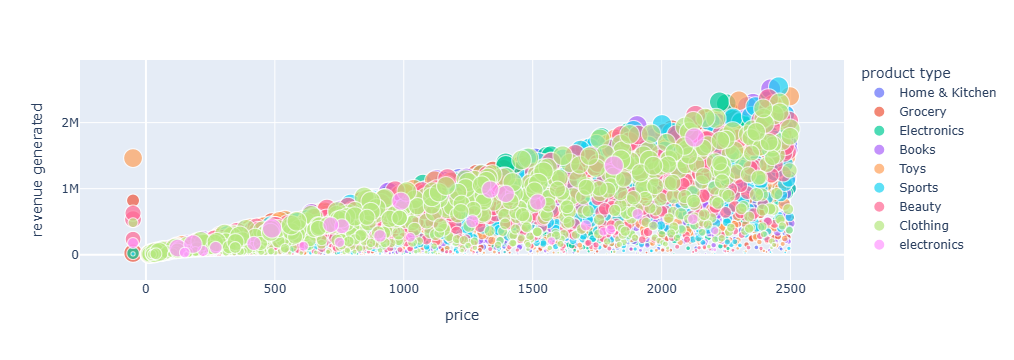

In [6]:
fig=px.scatter(df,x='price',y='revenue generated',color='product type',size='number of product sold',hover_data=['number of product sold'])
fig.show()

# Analyse the sales by product type

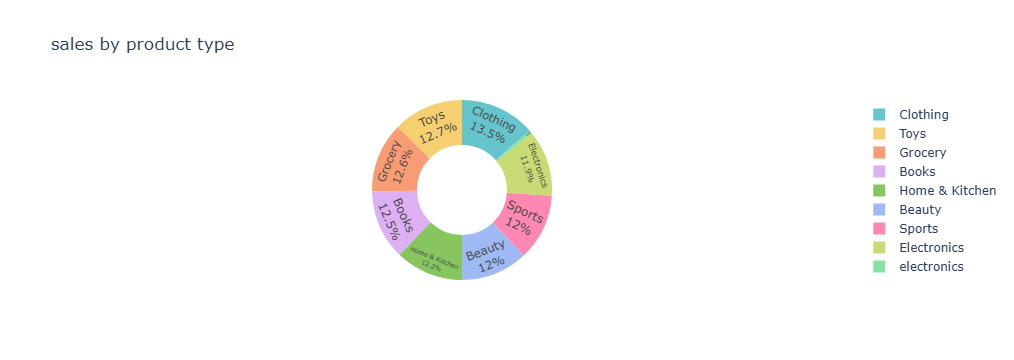

In [9]:
sales_data=df.groupby('product type')['number of product sold'].sum().reset_index()
pie_chart=px.pie(sales_data,values='number of product sold',names='product type',title='sales by product type',hover_data=['number of product sold'],hole=0.5,
                 color_discrete_sequence=px.colors.qualitative.Pastel)
pie_chart.update_traces(textposition='inside',textinfo='percent+label')
pie_chart.show()

# Total revenue generated by SKU

# 

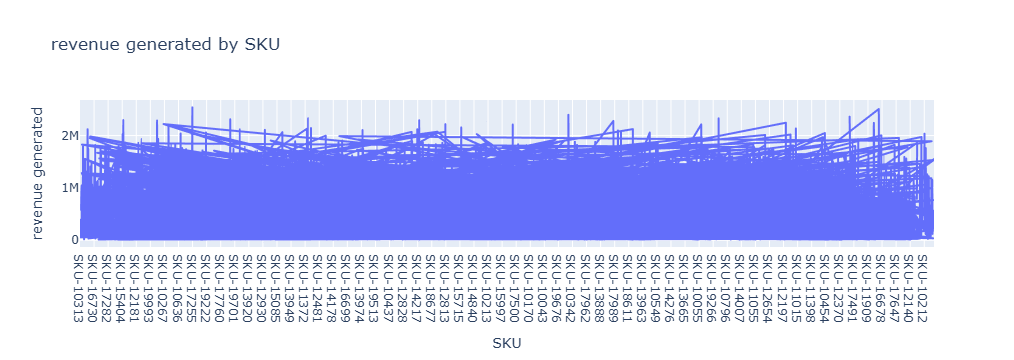

In [14]:
revenue_chart=px.line(df,x="SKU",y='revenue generated',title='revenue generated by SKU')
revenue_chart.show()

In [15]:
df.head()

,product type,SKU,price,availability,number of product sold,revenue generated,customer demographics,stock levels,lead times,order quantities,location,lead time,production volumes,manufacturing lead time,manufacturing costs,inspection results,defect rates,transportation modes,routes,costs
0,Home & Kitchen,SKU-10313,224.04,Out of Stock,834,156908.41,18-25,267.0,3,132,San Francisco,NaN,1590,6,138.89,Pending,NaN,Sea,Route-F,452.00
1,Grocery,SKU-16751,176.34,In Stock,821,128445.35,36-45,NaN,22,313,Toronto,37.0,5523,9,130.28,Pending,0.0140,Sea,Route-A,837.90
2,Electronics,SKU-15076,828.70,In Stock,597,383272.20,18-25,1258.0,1,421,Sydney,13.0,2884,13,590.11,Fail,0.0161,Rail,Route-E,838.48
3,Books,SKU-13896,1230.54,Out of Stock,324,327913.49,26-35,527.0,12,427,Atlanta,6.0,2531,12,857.27,Pass,0.1070,Rail,Route-E,987.10
4,Toys,SKU-15402,NaN,Limited Stock,396,79642.90,56+,307.0,11,42,Atlanta,43.0,2417,12,109.59,Pending,0.1048,Sea,Route-B,599.09


# Cost of distribution by transportation modes

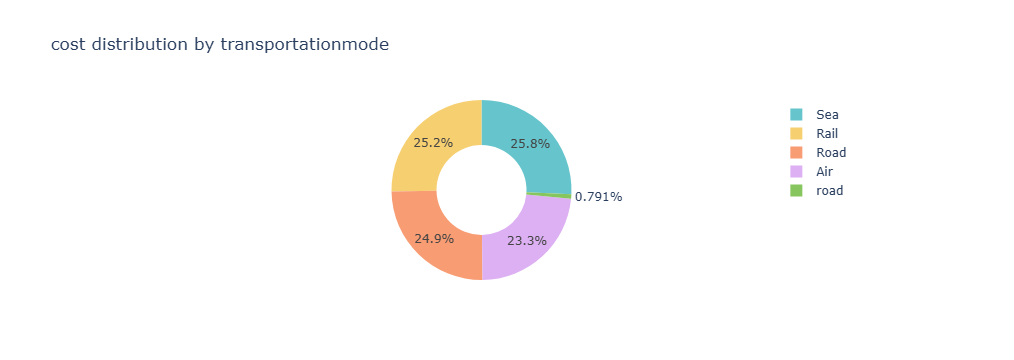

In [16]:
transportation_chart=px.pie(df,values='costs',names='transportation modes',title='cost distribution by transportationmode',hole=0.5,color_discrete_sequence=px.colors.qualitative.Pastel)
transportation_chart.show()

# Analyse the defect rate of products

In [17]:
df.head()

,product type,SKU,price,availability,number of product sold,revenue generated,customer demographics,stock levels,lead times,order quantities,location,lead time,production volumes,manufacturing lead time,manufacturing costs,inspection results,defect rates,transportation modes,routes,costs
0,Home & Kitchen,SKU-10313,224.04,Out of Stock,834,156908.41,18-25,267.0,3,132,San Francisco,NaN,1590,6,138.89,Pending,NaN,Sea,Route-F,452.00
1,Grocery,SKU-16751,176.34,In Stock,821,128445.35,36-45,NaN,22,313,Toronto,37.0,5523,9,130.28,Pending,0.0140,Sea,Route-A,837.90
2,Electronics,SKU-15076,828.70,In Stock,597,383272.20,18-25,1258.0,1,421,Sydney,13.0,2884,13,590.11,Fail,0.0161,Rail,Route-E,838.48
3,Books,SKU-13896,1230.54,Out of Stock,324,327913.49,26-35,527.0,12,427,Atlanta,6.0,2531,12,857.27,Pass,0.1070,Rail,Route-E,987.10
4,Toys,SKU-15402,NaN,Limited Stock,396,79642.90,56+,307.0,11,42,Atlanta,43.0,2417,12,109.59,Pending,0.1048,Sea,Route-B,599.09


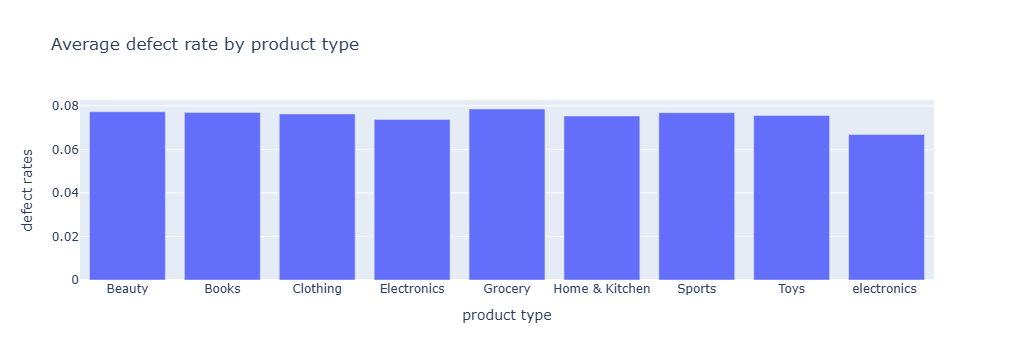

In [19]:
defect_rates_by_product=df.groupby('product type')['defect rates'].mean().reset_index()
fig=px.bar(defect_rates_by_product,x='product type',y='defect rates',title="Average defect rate by product type")
fig.show()